In [1]:
!pip install ultralytics opencv-python matplotlib pandas seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 14.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ultralytics import YOLO
from google.colab import files
from collections import Counter
from PIL import Image

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
if torch.cuda.is_available():
    device = 0
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    device = "cpu"
    print("GPU not available. Using CPU.")

GPU not available. Using CPU.


In [4]:
model = YOLO("yolo11n.pt")

print("COCO pretrained YOLO model loaded!")

# Display all COCO categories
print("\nCOCO Categories:")

for class_id, class_name in model.names.items():
    print(class_id, ":", class_name)

COCO pretrained YOLO model loaded!

COCO Categories:
0 : person
1 : bicycle
2 : car
3 : motorcycle
4 : airplane
5 : bus
6 : train
7 : truck
8 : boat
9 : traffic light
10 : fire hydrant
11 : stop sign
12 : parking meter
13 : bench
14 : bird
15 : cat
16 : dog
17 : horse
18 : sheep
19 : cow
20 : elephant
21 : bear
22 : zebra
23 : giraffe
24 : backpack
25 : umbrella
26 : handbag
27 : tie
28 : suitcase
29 : frisbee
30 : skis
31 : snowboard
32 : sports ball
33 : kite
34 : baseball bat
35 : baseball glove
36 : skateboard
37 : surfboard
38 : tennis racket
39 : bottle
40 : wine glass
41 : cup
42 : fork
43 : knife
44 : spoon
45 : bowl
46 : banana
47 : apple
48 : sandwich
49 : orange
50 : broccoli
51 : carrot
52 : hot dog
53 : pizza
54 : donut
55 : cake
56 : chair
57 : couch
58 : potted plant
59 : bed
60 : dining table
61 : toilet
62 : tv
63 : laptop
64 : mouse
65 : remote
66 : keyboard
67 : cell phone
68 : microwave
69 : oven
70 : toaster
71 : sink
72 : refrigerator
73 : book
74 : clock
75 : vas

Saving hhhhhh.jpg to hhhhhh.jpg
Uploaded Image: hhhhhh.jpg


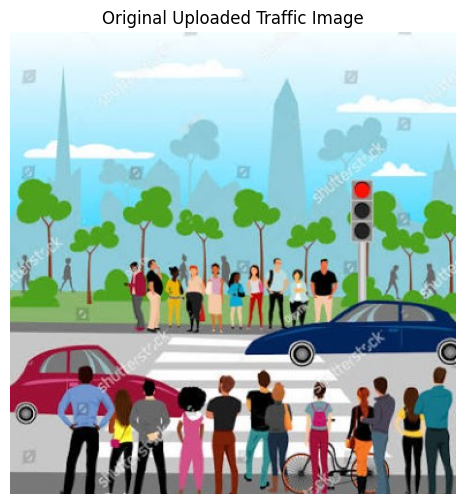

In [5]:
uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Uploaded Image:", filename)

# Read image
image = cv2.imread(filename)

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display original image
plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.title("Original Uploaded Traffic Image")
plt.axis("off")
plt.show()

In [6]:
results = model.predict(
    source=image,
    conf=0.25,
    device=device
)

result = results[0]

print("Object detection completed!")


0: 640x640 22 persons, 1 bicycle, 1 traffic light, 1 backpack, 577.0ms
Speed: 20.2ms preprocess, 577.0ms inference, 22.0ms postprocess per image at shape (1, 3, 640, 640)
Object detection completed!


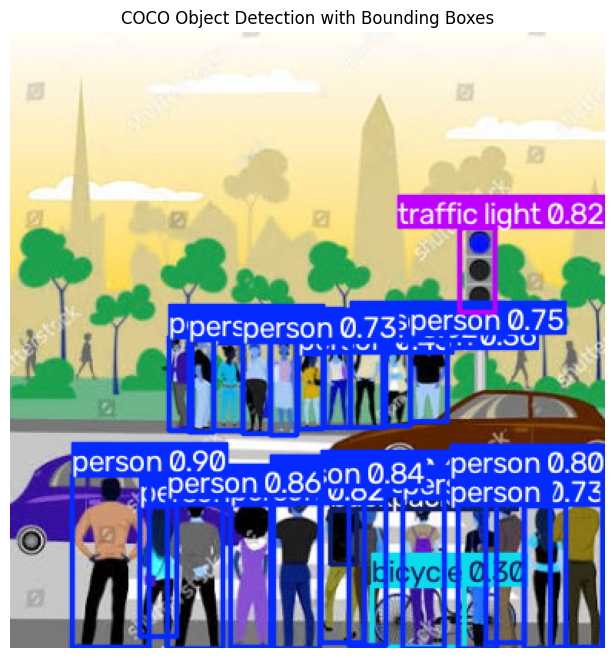

In [7]:
annotated_image = result.plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 8))

plt.imshow(annotated_image)

plt.title("COCO Object Detection with Bounding Boxes")

plt.axis("off")

plt.show()

In [8]:
detections = []

for box in result.boxes:

    class_id = int(box.cls[0])

    category = result.names[class_id]

    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    detections.append({
        "Category ID": class_id,
        "Object Category": category,
        "Confidence (%)": round(confidence * 100, 2),
        "X_min": round(x1, 2),
        "Y_min": round(y1, 2),
        "X_max": round(x2, 2),
        "Y_max": round(y2, 2)
    })

df = pd.DataFrame(detections)

print("COCO Bounding Box Annotations")

display(df)

COCO Bounding Box Annotations


,Category ID,Object Category,Confidence (%),X_min,Y_min,X_max,Y_max
0,0,person,90.45,40.43,288.65,90.73,400.87
1,0,person,86.12,102.71,302.31,139.00,401.00
2,0,person,84.49,169.57,296.61,201.20,401.00
3,9,traffic light,82.16,293.00,127.89,315.48,182.17
4,0,person,81.51,143.96,307.18,171.06,400.52
5,0,person,79.85,351.24,289.48,385.59,400.92
6,0,person,74.52,260.61,196.59,284.44,253.63
7,0,person,73.49,334.08,308.66,361.72,401.00
8,0,person,72.98,151.96,201.93,169.23,261.87
9,0,person,72.70,255.88,303.20,282.34,401.00


In [9]:
object_counts = Counter(
    item["Object Category"]
    for item in detections
)

print("TOTAL OBJECTS:", len(detections))

print("\nCATEGORY-WISE COUNTS")

for category, count in object_counts.items():

    print(category, ":", count)

TOTAL OBJECTS: 25

CATEGORY-WISE COUNTS
person : 22
traffic light : 1
bicycle : 1
backpack : 1


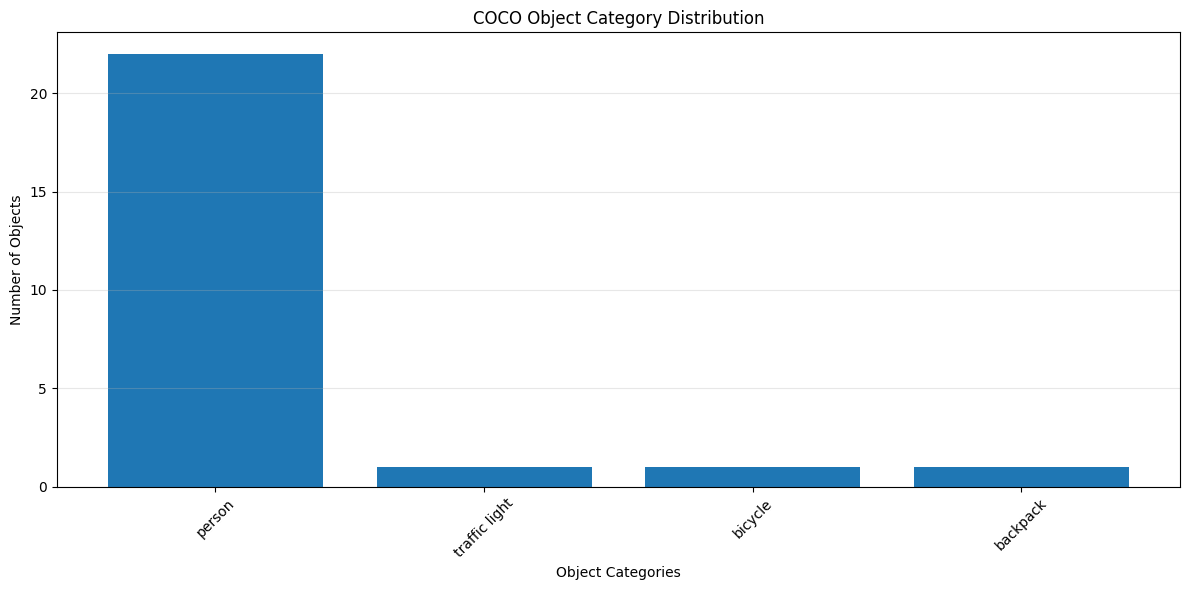

In [10]:
plt.figure(figsize=(12, 6))

if object_counts:

    categories = list(object_counts.keys())
    counts = list(object_counts.values())

    plt.bar(categories, counts)

    plt.title("COCO Object Category Distribution")

    plt.xlabel("Object Categories")
    plt.ylabel("Number of Objects")

    plt.xticks(rotation=45)

    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.show()

else:
    print("No objects detected!")

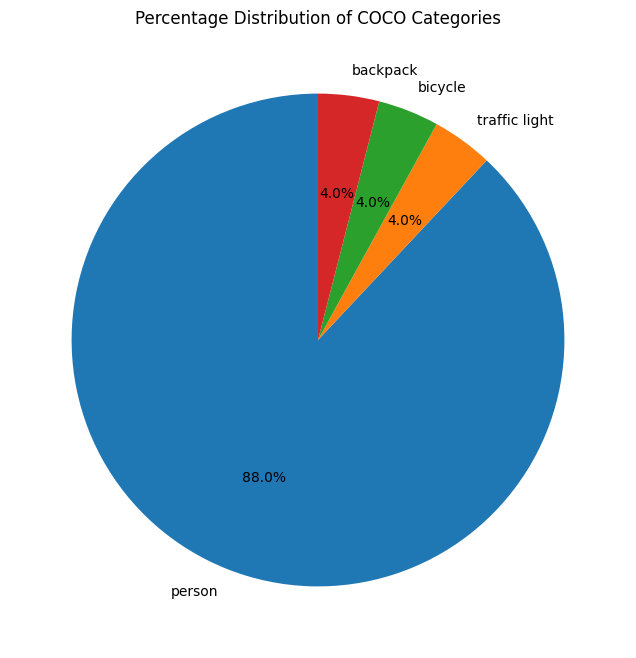

In [11]:
if object_counts:

    plt.figure(figsize=(8, 8))

    plt.pie(
        object_counts.values(),
        labels=object_counts.keys(),
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Percentage Distribution of COCO Categories")

    plt.show()

else:
    print("No objects available for pie chart.")

In [12]:
print("=" * 45)
print("       VISIONPORT - COCO EXPLORATION")
print("=" * 45)

print("Uploaded Image:", filename)

print("Total Objects Detected:", len(detections))

print("Unique Categories:", len(object_counts))

print("\nCategory-wise Object Counts:")

for category, count in object_counts.items():

    print(f"{category}: {count}")

print("\nBounding Box Annotations:", len(detections))

print("=" * 45)
print("       ANALYSIS COMPLETED")
print("=" * 45)

       VISIONPORT - COCO EXPLORATION
Uploaded Image: hhhhhh.jpg
Total Objects Detected: 25
Unique Categories: 4

Category-wise Object Counts:
person: 22
traffic light: 1
bicycle: 1
backpack: 1

Bounding Box Annotations: 25
       ANALYSIS COMPLETED
